# Impact des data centers : croisement avec des sources externes (points 7 à 11)
Prérequis : `pip install pandas numpy matplotlib folium` · `export_summary.csv` dans le même dossier.
Toutes les données externes sont rassemblées dans **un seul tableau** (cellule 0) avec leur source, leur année et leur périmètre, pour pouvoir les citer et les mettre à jour.

## 0. Chargement, style et tableau des données externes (à exécuter en premier)

In [1]:
import os, json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
from matplotlib.patches import Circle, Rectangle

# --- Direction artistique éditoriale (fond crème, cartes blanches, accents nets) ---
BG = "#FAF9F6"
CARD = "#FFFFFF"
INK = "#111827"
SUB = "#4B5563"
MUTED = "#9CA3AF"
GRID = "#E5E7EB"

TEAL = "#0D9488"
TEAL_DARK = "#115E59"
TEAL_SOFT = "#CCFBF1"
AMBER = "#EA580C"
AMBER_SOFT = "#FFEDD5"
BLUE = "#2563EB"
SLATE = "#334155"

plt.rcParams.update({
    "figure.facecolor": BG,
    "axes.facecolor": CARD,
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
    "font.size": 10.5,
    "text.color": INK,
    "axes.labelcolor": SUB,
    "axes.edgecolor": GRID,
    "axes.linewidth": 0.8,
    "savefig.dpi": 220,
})
os.makedirs("figures", exist_ok=True)

def fmt(v, d=0):
    return f"{v:,.{d}f}".replace(",", " ").replace(".", ",")

def add_header(fig, kicker, title, subtitle):
    fig.patches.append(Rectangle((0.03, 0.955), 0.045, 0.008, transform=fig.transFigure, facecolor=AMBER, edgecolor="none"))
    fig.text(0.082, 0.952, kicker.upper(), fontsize=8.5, fontweight="bold", color=AMBER)
    fig.text(0.03, 0.905, title, fontsize=15.5, fontweight="bold", color=INK)
    fig.text(0.03, 0.865, subtitle, fontsize=10.5, color=SUB)

def add_footer(fig, source):
    fig.text(0.03, 0.018, source, fontsize=8.5, color=MUTED)

# --- Tes données (France) ---
if os.path.exists("export_summary.csv"):
    df = pd.read_csv("export_summary.csv")
    df = df[df["country"] == "France"].copy()
    df["statut"] = np.where(df["progress_step"] == "operating", "En service", "En projet")
    df["mw"] = df["power_total_mw"].replace(0, np.nan)
    GW_SERVICE = df.loc[df.statut == "En service", "mw"].sum() / 1000
    GW_PROJET = df.loc[df.statut == "En projet", "mw"].sum() / 1000
    N_PROJ_SANS_MW = int(((df.statut == "En projet") & df.mw.isna()).sum())
else:
    df = pd.DataFrame(columns=["name", "country", "progress_step", "power_total_mw", "statut", "mw", "department", "city_code", "latitude", "longitude"])
    GW_SERVICE, GW_PROJET, N_PROJ_SANS_MW = 2.22, 7.39, 29

print(f"Données France : {GW_SERVICE:.2f} GW en service ; {GW_PROJET:.2f} GW en projet ({N_PROJ_SANS_MW} projets sans puissance renseignée)")

# --- Données externes sourcée ---
EXT = pd.DataFrame([
    ("Conso. data centers, sites dédiés", 4, 5, "TWh", 2024, "RTE, sites dédiés, hors salles internes", "RTE, Bilan prévisionnel 2025"),
    ("Conso. data centers, sites dédiés", 10, 15, "TWh", 2030, "10 si 30 % des projets aboutissent, 15 si 60 %", "RTE, Bilan prévisionnel 2025"),
    ("Conso. data centers, sites dédiés", 21, 32, "TWh", 2035, "selon les 2 trajectoires de décarbonation", "RTE, Bilan prévisionnel 2025"),
    ("Conso. data centers, périmètre large", 10, 10, "TWh", 2026, "≈ 2 % de la consommation, inclut les salles internes", "RTE (page grand public)"),
    ("Conso. data centers, périmètre large", 23, 28, "TWh", 2035, "périmètre large RTE", "RTE (page grand public)"),
    ("Consommation électrique France", 451, 451, "TWh", 2025, "consommation totale", "RTE, Bilan électrique 2025"),
    ("Consommation électrique France", 470, 510, "TWh", 2030, "trajectoire lente (470) / rapide (510)", "RTE, Bilan prévisionnel 2025"),
    ("Consommation électrique France", 505, 580, "TWh", 2035, "trajectoire lente (505) / rapide (580)", "RTE, Bilan prévisionnel 2025"),
    ("Parc nucléaire, puissance installée", 63, 63, "GW", 2025, "57 réacteurs, 18 centrales (≈ 1,1 GW par réacteur)", "EDF / RTE"),
    ("Production nucléaire", 373, 373, "TWh", 2025, "68,1 % de la production", "RTE, Bilan électrique 2025"),
    ("Raccordement réservé data centers", 18, 18, "GW", 2026, "≈ 80 projets ; 5 GW fin 2024", "RTE"),
    ("Puissance demandée data centers", 28.6, 28.6, "GW", 2026, "tous stades confondus", "RTE"),
    ("Intensité carbone électricité : Norvège", 28.1, 28.1, "gCO2e/kWh", 2025, "cycle de vie, production", "Ember 2026 / Our World in Data"),
    ("Intensité carbone électricité : France", 41.4, 41.4, "gCO2e/kWh", 2025, "cycle de vie", "Ember 2026 / Our World in Data"),
    ("Intensité carbone électricité : Allemagne", 330, 330, "gCO2e/kWh", 2025, "cycle de vie, production", "Ember 2026 / Our World in Data"),
    ("Intensité carbone électricité : États-Unis", 384, 384, "gCO2e/kWh", 2025, "cycle de vie, moyenne nationale", "Ember 2026 / Our World in Data"),
    ("Intensité carbone électricité : Monde", 458, 458, "gCO2e/kWh", 2025, "cycle de vie", "Ember 2026 / Our World in Data"),
    ("Intensité carbone électricité : Pologne", 589, 589, "gCO2e/kWh", 2025, "cycle de vie, production", "Ember 2026 / Our World in Data"),
    ("Llama 3.1 405B, entraînement", 30.84, 30.84, "M heures GPU", 2024, "H100, 700 W par GPU", "Meta, fiche du modèle"),
    ("Llama 3.1 405B, entraînement", 8930, 8930, "tCO2e", 2024, "émissions location-based", "Meta, fiche du modèle"),
    ("BLOOM 176B, entraînement", 50.5, 50.5, "tCO2e", 2022, "dont dynamique 24,7 / veille 14,6 / fabrication 11,2", "Luccioni et al., JMLR 2023"),
    ("Mistral Large 2, ACV", 20.4, 20.4, "ktCO2e", 2025, "entraînement + 18 mois d'usage", "Mistral AI / Carbone 4 / ADEME"),
    ("Mistral Large 2, part entraînement+usage", 85.5, 85.5, "% des GES", 2025, "matériel ≈ 11 %", "Mistral AI"),
    ("Mistral Large 2, 1 réponse de 400 tokens", 1.14, 1.14, "gCO2e", 2025, "impact marginal de l'inférence, ACV", "Mistral AI"),
    ("Gemini Apps, 1 prompt texte médian", 0.03, 0.03, "gCO2e", 2025, "0,24 Wh", "Google, août 2025"),
], columns=["indicateur", "valeur_basse", "valeur_haute", "unite", "annee", "perimetre", "source"])

def ext(ind, annee=None, col="valeur_basse", unite=None):
    s = EXT[EXT.indicateur == ind]
    if annee is not None: s = s[s.annee == annee]
    if unite is not None: s = s[s.unite == unite]
    return float(s.iloc[0][col])


Données France : 2.22 GW en service ; 7.39 GW en projet (29 projets sans puissance renseignée)


## 7. Équivalences : que représentent les projets en réacteurs et en TWh ?
Gauche : puissance en GW (capacité). Droite : énergie annuelle en TWh si les projets tournent à 50 %, 80 % ou 100 % de leur puissance. **Une capacité demandée n'est pas une consommation** : d'où les facteurs de charge.

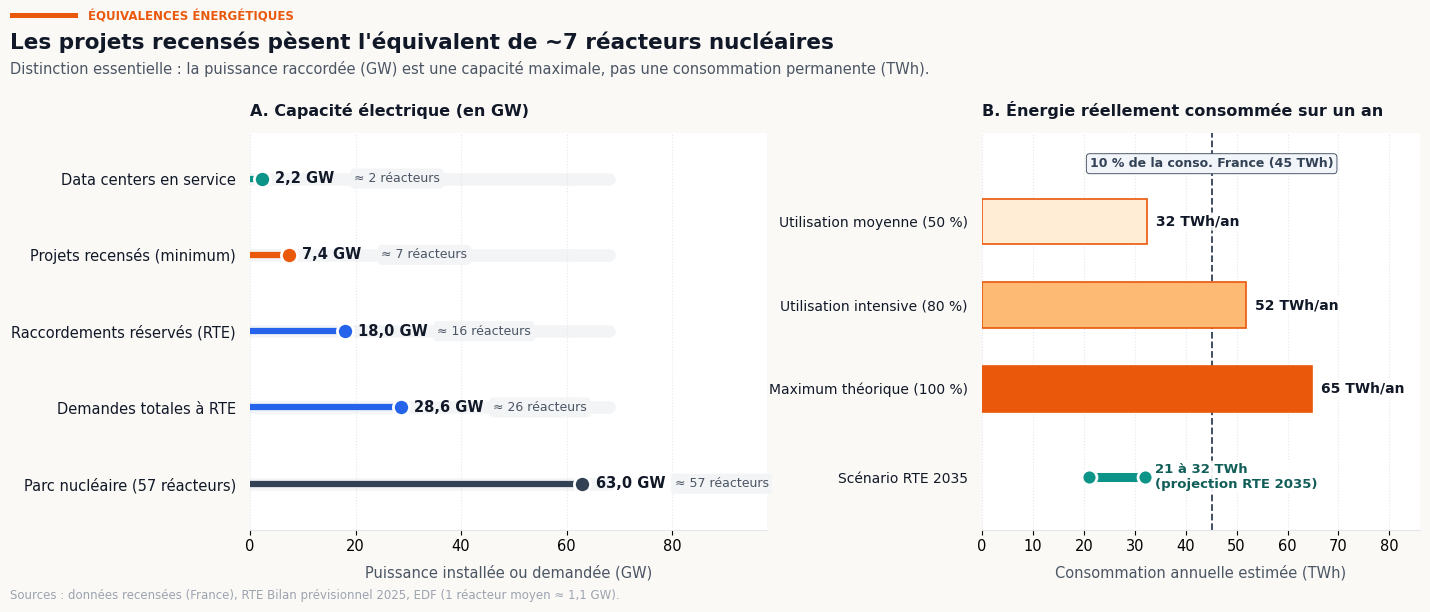

In [2]:
GW_NUC, N_REAC = ext("Parc nucléaire, puissance installée"), 57
GW_REACTEUR = GW_NUC / N_REAC
conso_fr = ext("Consommation électrique France", 2025)
rte_res, rte_dem = ext("Raccordement réservé data centers"), ext("Puissance demandée data centers")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [1.18, 1]})
fig.patch.set_facecolor(BG)

items = [
    ("Data centers en service", GW_SERVICE, TEAL),
    ("Projets recensés (minimum)", GW_PROJET, AMBER),
    ("Raccordements réservés (RTE)", rte_res, BLUE),
    ("Demandes totales à RTE", rte_dem, BLUE),
    ("Parc nucléaire (57 réacteurs)", GW_NUC, SLATE),
]
y = np.arange(len(items))[::-1]
ax1.set_facecolor(CARD)

for yi, (lab, v, col) in zip(y, items):
    ax1.plot([0, 68], [yi, yi], color="#F3F4F6", lw=9, solid_capstyle="round", zorder=1)
    ax1.plot([0, v], [yi, yi], color=col, lw=4.5, solid_capstyle="round", zorder=2)
    ax1.scatter([v], [yi], color=col, s=135, zorder=3, edgecolors="white", linewidth=2)
    n_reac_eq = v / GW_REACTEUR
    ax1.text(v + 2.5, yi, f"{fmt(v, 1)} GW", va="center", fontsize=10.5, fontweight="bold", color=INK)
    ax1.text(v + 17.5, yi, f"≈ {fmt(n_reac_eq, 0)} réacteurs", va="center", fontsize=9, color=SUB,
             bbox=dict(boxstyle="round,pad=0.28", fc="#F3F4F6", ec="none"))

ax1.set_yticks(y, [i[0] for i in items])
ax1.set_yticklabels([i[0] for i in items], fontsize=10.5, fontweight="medium", color=INK)
ax1.set_xlim(0, 98)
ax1.set_ylim(-0.6, len(items) - 0.4)
ax1.set_xlabel("Puissance installée ou demandée (GW)", labelpad=8)
ax1.set_title("A. Capacité électrique (en GW)", loc="left", fontsize=11.5, fontweight="bold", pad=12)
ax1.xaxis.grid(True, color=GRID, ls=":", zorder=0)
for s in ("top", "right", "left"): ax1.spines[s].set_visible(False)
ax1.tick_params(axis="y", length=0, pad=10)

h_an = 8.76
t50, t80, t100 = GW_PROJET * h_an * 0.5, GW_PROJET * h_an * 0.8, GW_PROJET * h_an * 1.0
rte35_lo = ext("Conso. data centers, sites dédiés", 2035, "valeur_basse")
rte35_hi = ext("Conso. data centers, sites dédiés", 2035, "valeur_haute")

ax2.set_facecolor(CARD)
scenarios = [
    ("Utilisation moyenne (50 %)", t50, AMBER_SOFT),
    ("Utilisation intensive (80 %)", t80, "#FDBA74"),
    ("Maximum théorique (100 %)", t100, AMBER),
]
y2 = [2.6, 1.8, 1.0]
for yi, (lab, val, c_fill) in zip(y2, scenarios):
    ax2.barh(yi, val, height=0.44, color=c_fill, edgecolor=AMBER, linewidth=1.2, zorder=3)
    ax2.text(val + 1.8, yi, f"{fmt(val, 0)} TWh/an", va="center", fontsize=10, fontweight="bold", color=INK,
             bbox=dict(boxstyle="round,pad=0.15", fc=CARD, ec="none", alpha=0.85))

ax2.plot([rte35_lo, rte35_hi], [0.15, 0.15], color=TEAL, lw=6.5, solid_capstyle="round", zorder=3)
ax2.scatter([rte35_lo, rte35_hi], [0.15, 0.15], color=TEAL, s=115, edgecolors="white", linewidth=2, zorder=4)
ax2.text(rte35_hi + 2.0, 0.15, f"{fmt(rte35_lo, 0)} à {fmt(rte35_hi, 0)} TWh\n(projection RTE 2035)", va="center", fontsize=9.5, fontweight="bold", color=TEAL_DARK,
         bbox=dict(boxstyle="round,pad=0.2", fc=CARD, ec="none", alpha=0.9))

rep10 = 0.10 * conso_fr
ax2.axvline(rep10, color=SLATE, ls="--", lw=1.3, zorder=2)
ax2.text(rep10, 3.12, f"10 % de la conso. France ({fmt(rep10, 0)} TWh)", ha="center", fontsize=9,
         fontweight="bold", color=SLATE, bbox=dict(boxstyle="round,pad=0.28", fc="#F1F5F9", ec=SLATE, lw=0.6))

ax2.set_yticks([2.6, 1.8, 1.0, 0.15], [s[0] for s in scenarios] + ["Scénario RTE 2035"])
ax2.set_yticklabels([s[0] for s in scenarios] + ["Scénario RTE 2035"], fontsize=10, fontweight="medium", color=INK)
ax2.set_xlim(0, 86)
ax2.set_ylim(-0.35, 3.45)
ax2.set_xlabel("Consommation annuelle estimée (TWh)", labelpad=8)
ax2.set_title("B. Énergie réellement consommée sur un an", loc="left", fontsize=11.5, fontweight="bold", pad=12)
ax2.xaxis.grid(True, color=GRID, ls=":", zorder=0)
for s in ("top", "right", "left"): ax2.spines[s].set_visible(False)
ax2.tick_params(axis="y", length=0, pad=10)

add_header(fig, "Équivalences énergétiques",
           f"Les projets recensés pèsent l'équivalent de ~{fmt(GW_PROJET / GW_REACTEUR, 0)} réacteurs nucléaires",
           "Distinction essentielle : la puissance raccordée (GW) est une capacité maximale, pas une consommation permanente (TWh).")
add_footer(fig, "Sources : données recensées (France), RTE Bilan prévisionnel 2025, EDF (1 réacteur moyen ≈ 1,1 GW).")
plt.subplots_adjust(top=0.77, bottom=0.13, left=0.19, right=0.97, wspace=0.45)
plt.savefig("figures/7_equivalences_design.png", bbox_inches="tight")
plt.show()


## 8. Part des data centers dans la consommation électrique française
Gauche : fourchettes RTE en TWh. Droite : « waffle » (1 carré = 1 % de la consommation nationale).

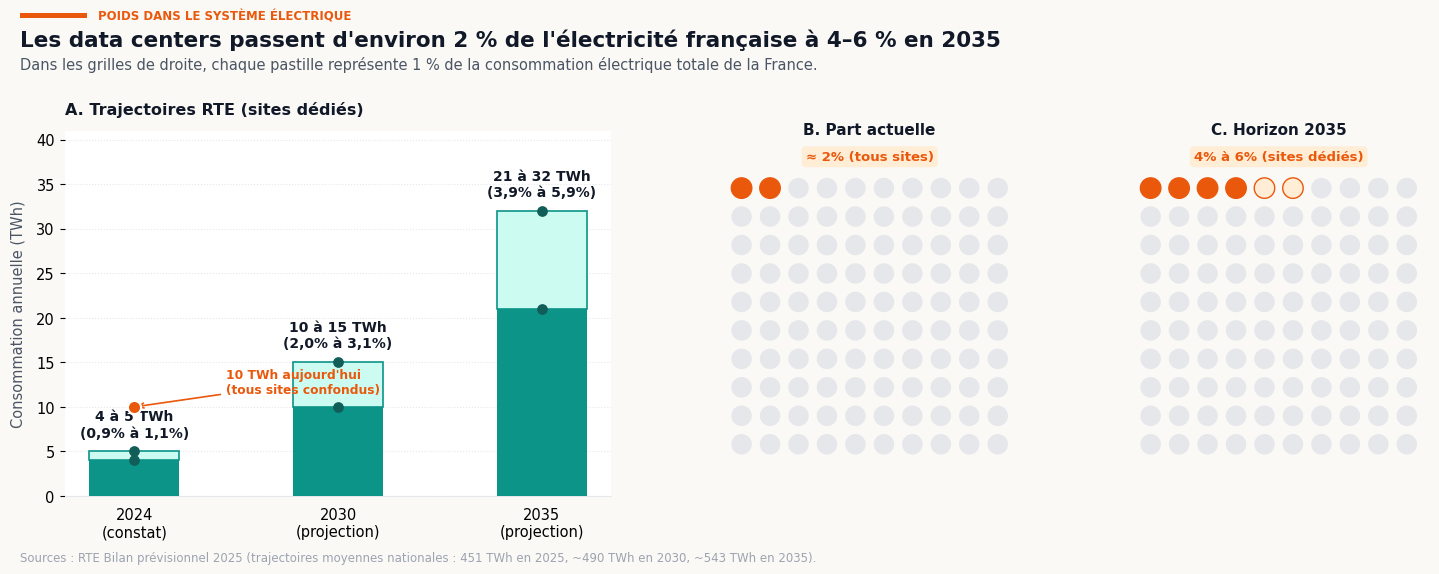

In [4]:
conso = {
    2024: ext("Consommation électrique France", 2025),
    2030: (ext("Consommation électrique France", 2030, "valeur_basse") + ext("Consommation électrique France", 2030, "valeur_haute")) / 2,
    2035: (ext("Consommation électrique France", 2035, "valeur_basse") + ext("Consommation électrique France", 2035, "valeur_haute")) / 2,
}
dc = {a: (ext("Conso. data centers, sites dédiés", a, "valeur_basse"), ext("Conso. data centers, sites dédiés", a, "valeur_haute")) for a in (2024, 2030, 2035)}
part = {a: (dc[a][0] / conso[a], dc[a][1] / conso[a]) for a in dc}
part_large_auj = ext("Conso. data centers, périmètre large", 2026) / conso[2024]

fig = plt.figure(figsize=(15, 5.8))
fig.patch.set_facecolor(BG)
gs = fig.add_gridspec(1, 3, width_ratios=[1.45, 0.8, 0.8], wspace=0.28)

ax = fig.add_subplot(gs[0])
ax.set_facecolor(CARD)
annees = ["2024\n(constat)", "2030\n(projection)", "2035\n(projection)"]
xs = np.arange(3)

for x, a in zip(xs, (2024, 2030, 2035)):
    lo, hi = dc[a]
    ax.bar(x, lo, width=0.44, color=TEAL, zorder=3)
    ax.bar(x, hi - lo, bottom=lo, width=0.44, color=TEAL_SOFT, edgecolor=TEAL, linewidth=1.2, zorder=3)
    ax.scatter([x, x], [lo, hi], color=TEAL_DARK, s=45, zorder=4)
    pct_str = f"{part[a][0]:.1%} à {part[a][1]:.1%}".replace(".", ",")
    ax.text(x, hi + 1.3, f"{fmt(lo, 0)} à {fmt(hi, 0)} TWh\n({pct_str})", ha="center", va="bottom", fontsize=10, fontweight="bold", color=INK)

large_2026 = ext("Conso. data centers, périmètre large", 2026)
ax.scatter([0], [large_2026], color=AMBER, s=90, zorder=5, edgecolors="white", linewidth=1.5)
ax.annotate(f"{fmt(large_2026, 0)} TWh aujourd'hui\n(tous sites confondus)", xy=(0, large_2026), xytext=(0.45, large_2026 + 1.5),
            fontsize=8.8, fontweight="bold", color=AMBER,
            arrowprops=dict(arrowstyle="->", color=AMBER, lw=1.2))

ax.set_xticks(xs, annees)
ax.set_ylim(0, 41)
ax.set_ylabel("Consommation annuelle (TWh)", labelpad=8)
ax.set_title("A. Trajectoires RTE (sites dédiés)", loc="left", fontsize=11.5, fontweight="bold", pad=12)
ax.yaxis.grid(True, color=GRID, ls=":", zorder=0)
for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
ax.tick_params(axis="x", length=0, pad=8)

def dot_matrix(axw, n_solid, n_soft, titre, badge_txt):
    axw.set_facecolor(CARD)
    for i in range(100):
        r, c = divmod(i, 10)
        if i < n_solid:
            col, ec = AMBER, AMBER
        elif i < n_soft:
            col, ec = AMBER_SOFT, AMBER
        else:
            col, ec = "#E5E7EB", "none"
        axw.add_patch(Circle((c + 0.5, 9.5 - r), 0.36, facecolor=col, edgecolor=ec, lw=1.0))
    axw.set_xlim(-0.3, 10.3)
    axw.set_ylim(-0.3, 10.5)
    axw.set_aspect("equal")
    axw.axis("off")
    axw.set_title(titre, fontsize=11, fontweight="bold", color=INK, pad=18)
    axw.text(5, 10.6, badge_txt, ha="center", va="center", fontsize=9.5, fontweight="bold", color=AMBER,
             bbox=dict(boxstyle="round,pad=0.3", fc=AMBER_SOFT, ec="none"))

dot_matrix(fig.add_subplot(gs[1]), round(part_large_auj * 100), round(part_large_auj * 100),
           "B. Part actuelle", f"≈ {part_large_auj:.0%} (tous sites)")
dot_matrix(fig.add_subplot(gs[2]), round(part[2035][0] * 100), round(part[2035][1] * 100),
           "C. Horizon 2035", f"{part[2035][0]:.0%} à {part[2035][1]:.0%} (sites dédiés)")

add_header(fig, "Poids dans le système électrique",
           "Les data centers passent d'environ 2 % de l'électricité française à 4–6 % en 2035",
           "Dans les grilles de droite, chaque pastille représente 1 % de la consommation électrique totale de la France.")
add_footer(fig, "Sources : RTE Bilan prévisionnel 2025 (trajectoires moyennes nationales : 451 TWh en 2025, ~490 TWh en 2030, ~543 TWh en 2035).")
plt.subplots_adjust(top=0.76, bottom=0.13, left=0.06, right=0.97)
plt.savefig("figures/8_part_consommation_design.png", bbox_inches="tight")
plt.show()


## 9. Intensité carbone : la même charge de calcul, selon le pays
On rejoue **le même calcul** dans chaque pays : l'entraînement de Llama 3.1 405B, puis 1 million de requêtes. Seul le mix électrique change.

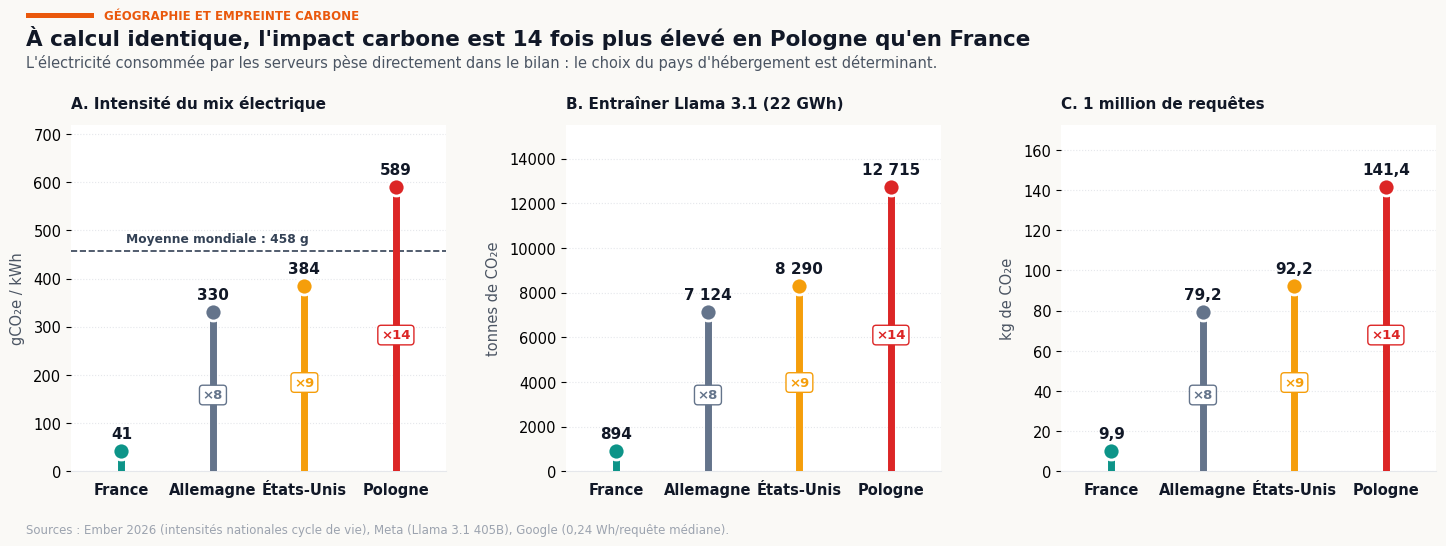

In [5]:
pays = [
    ("France", "Intensité carbone électricité : France"),
    ("Allemagne", "Intensité carbone électricité : Allemagne"),
    ("États-Unis", "Intensité carbone électricité : États-Unis"),
    ("Pologne", "Intensité carbone électricité : Pologne"),
]
noms = [p[0] for p in pays]
g_kwh = np.array([ext(p[1]) for p in pays])
monde = ext("Intensité carbone électricité : Monde")
E_TRAIN_GWH = ext("Llama 3.1 405B, entraînement", unite="M heures GPU") * 0.700
t_train = E_TRAIN_GWH * 1e6 * g_kwh / 1e6
kg_1M = 0.24e-3 * 1e6 * g_kwh / 1e3
cols_p = [TEAL, "#64748B", "#F59E0B", "#DC2626"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
fig.patch.set_facecolor(BG)

def plot_lollipop_v(ax, vals, titre, unite, dec=0, show_monde=False):
    ax.set_facecolor(CARD)
    xs = np.arange(len(noms))
    for x, v, c in zip(xs, vals, cols_p):
        ax.plot([x, x], [0, v], color=c, lw=5, solid_capstyle="round", zorder=3)
        ax.scatter([x], [v], color=c, s=150, edgecolors="white", linewidth=2, zorder=4)
        ax.text(x, v + max(vals) * 0.045, fmt(v, dec), ha="center", fontsize=11, fontweight="bold", color=INK)
        if v != vals[0]:
            ax.text(x, v * 0.48, f"×{v / vals[0]:.0f}", ha="center", va="center", fontsize=9.5,
                    fontweight="bold", color=c,
                    bbox=dict(boxstyle="round,pad=0.25", fc="white", ec=c, lw=1.0), zorder=5)
    if show_monde:
        ax.axhline(monde, color=SLATE, ls="--", lw=1.2, zorder=2)
        ax.text(0.05, monde + max(vals) * 0.03, f"Moyenne mondiale : {fmt(monde, 0)} g",
                fontsize=8.8, fontweight="bold", color=SLATE)
    ax.set_xticks(xs, noms)
    ax.set_xticklabels(noms, fontsize=10.5, fontweight="bold", color=INK)
    ax.set_ylim(0, max(vals) * 1.22)
    ax.set_xlim(-0.55, 3.55)
    ax.set_ylabel(unite, labelpad=6)
    ax.set_title(titre, loc="left", fontsize=11, fontweight="bold", pad=12)
    ax.yaxis.grid(True, color=GRID, ls=":", zorder=0)
    for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
    ax.tick_params(axis="x", length=0, pad=8)

plot_lollipop_v(axes[0], g_kwh, "A. Intensité du mix électrique", "gCO₂e / kWh", dec=0, show_monde=True)
plot_lollipop_v(axes[1], t_train, f"B. Entraîner Llama 3.1 ({fmt(E_TRAIN_GWH, 0)} GWh)", "tonnes de CO₂e", dec=0)
plot_lollipop_v(axes[2], kg_1M, "C. 1 million de requêtes", "kg de CO₂e", dec=1)

add_header(fig, "Géographie et empreinte carbone",
           "À calcul identique, l'impact carbone est 14 fois plus élevé en Pologne qu'en France",
           "L'électricité consommée par les serveurs pèse directement dans le bilan : le choix du pays d'hébergement est déterminant.")
add_footer(fig, "Sources : Ember 2026 (intensités nationales cycle de vie), Meta (Llama 3.1 405B), Google (0,24 Wh/requête médiane).")
plt.subplots_adjust(top=0.76, bottom=0.13, left=0.06, right=0.97, wspace=0.32)
plt.savefig("figures/9_intensite_carbone_design.png", bbox_inches="tight")
plt.show()


## 10. Cycle de vie : entraînement, fabrication, inférence
**Attention à ce que disent (et ne disent pas) les sources.** L'étude Mistral regroupe entraînement et 18 mois d'usage dans un même chiffre ; elle ne permet donc pas, seule, de montrer que « l'usage domine l'entraînement ». On présente donc : (a) la répartition publiée pour BLOOM et Mistral, et (b) un **calcul de seuil** : à partir de combien de requêtes l'inférence cumulée dépasse-t-elle l'entraînement ?

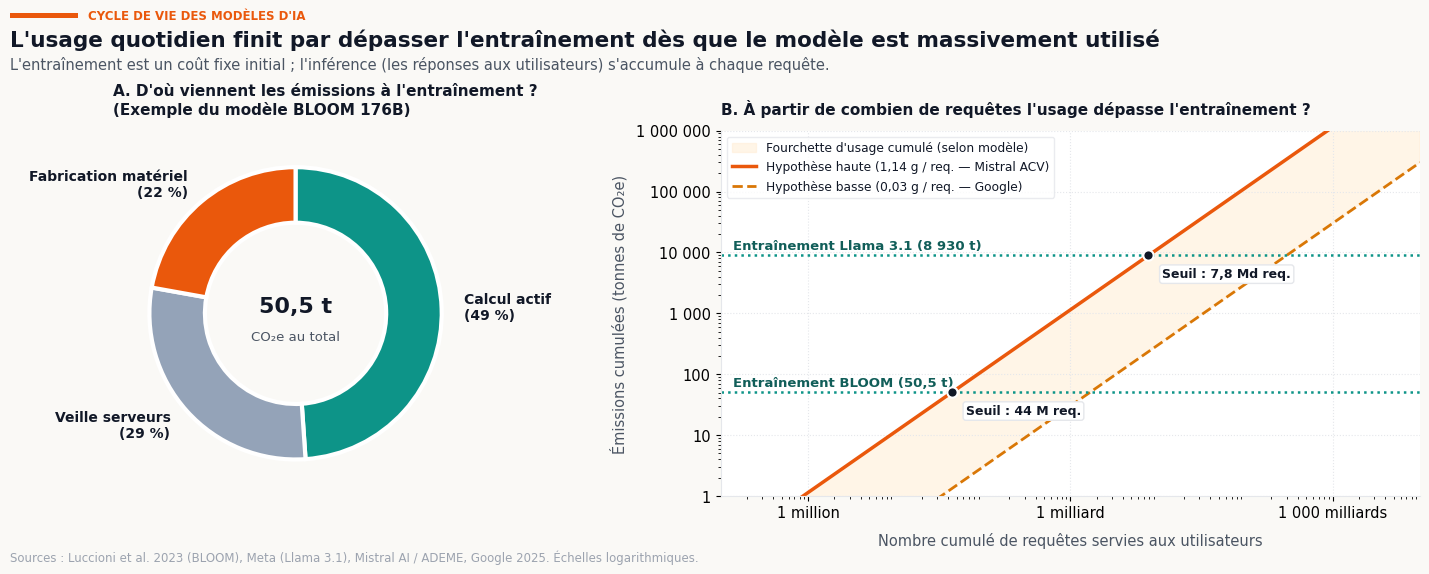

In [6]:
T_BLOOM = ext("BLOOM 176B, entraînement")
T_LLAMA = ext("Llama 3.1 405B, entraînement", unite="tCO2e")
E_MISTRAL = ext("Mistral Large 2, 1 réponse de 400 tokens")
E_GOOGLE = ext("Gemini Apps, 1 prompt texte médian")

fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(15, 5.8), gridspec_kw={"width_ratios": [0.95, 1.3]})
fig.patch.set_facecolor(BG)

ax_l.set_facecolor(CARD)
sizes = [24.7, 14.6, 11.2]
labels_d = ["Calcul actif\n(49 %)", "Veille serveurs\n(29 %)", "Fabrication matériel\n(22 %)"]
cols_d = [TEAL, "#94A3B8", AMBER]

ax_l.pie(
    sizes, labels=labels_d, colors=cols_d, startangle=90, counterclock=False,
    wedgeprops=dict(width=0.38, edgecolor="white", linewidth=3),
    textprops=dict(fontsize=10, fontweight="bold", color=INK), labeldistance=1.15
)
ax_l.text(0, 0.05, f"{fmt(T_BLOOM, 1)} t", ha="center", va="center", fontsize=16, fontweight="bold", color=INK)
ax_l.text(0, -0.16, "CO₂e au total", ha="center", va="center", fontsize=9.5, color=SUB)
ax_l.set_title("A. D'où viennent les émissions à l'entraînement ?\n(Exemple du modèle BLOOM 176B)", loc="left", fontsize=11, fontweight="bold", pad=12)

ax_r.set_facecolor(CARD)
N = np.logspace(5, 13, 200)
ax_r.fill_between(N, E_GOOGLE * N / 1e6, E_MISTRAL * N / 1e6, color=AMBER_SOFT, alpha=0.55, label="Fourchette d'usage cumulé (selon modèle)")
ax_r.plot(N, E_MISTRAL * N / 1e6, color=AMBER, lw=2.5, label=f"Hypothèse haute ({fmt(E_MISTRAL, 2)} g / req. — Mistral ACV)")
ax_r.plot(N, E_GOOGLE * N / 1e6, color="#D97706", ls="--", lw=2.0, label=f"Hypothèse basse ({fmt(E_GOOGLE, 2)} g / req. — Google)")

for T, nom, y_off in [(T_BLOOM, f"Entraînement BLOOM ({fmt(T_BLOOM, 1)} t)", 1.25),
                       (T_LLAMA, f"Entraînement Llama 3.1 ({fmt(T_LLAMA, 0)} t)", 1.25)]:
    ax_r.axhline(T, color=TEAL, lw=1.8, ls=":", zorder=2)
    ax_r.text(1.4e5, T * y_off, nom, fontsize=9.5, fontweight="bold", color=TEAL_DARK)
    n_m = T * 1e6 / E_MISTRAL
    ax_r.scatter([n_m], [T], color=INK, s=55, edgecolors="white", lw=1.5, zorder=5)
    lbl_n = f"{fmt(n_m / 1e6, 0)} M req." if n_m < 1e9 else f"{fmt(n_m / 1e9, 1)} Md req."
    ax_r.annotate(f"Seuil : {lbl_n}", (n_m, T), xytext=(10, -16), textcoords="offset points",
                  fontsize=9, fontweight="bold", color=INK,
                  bbox=dict(boxstyle="round,pad=0.22", fc="white", ec=GRID))

ax_r.set_xscale("log")
ax_r.set_yscale("log")
ax_r.set_xlim(1e5, 1e13)
ax_r.set_ylim(1, 1e6)
ax_r.set_xlabel("Nombre cumulé de requêtes servies aux utilisateurs", labelpad=8)
ax_r.set_ylabel("Émissions cumulées (tonnes de CO₂e)", labelpad=6)
ax_r.xaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: {1e6: "1 million", 1e9: "1 milliard", 1e12: "1 000 milliards"}.get(v, "")))
ax_r.xaxis.set_major_locator(mt.FixedLocator([1e6, 1e9, 1e12]))
ax_r.yaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: fmt(v, 0)))
ax_r.grid(True, which="major", color=GRID, ls=":", zorder=0)
ax_r.legend(frameon=True, facecolor="white", edgecolor=GRID, loc="upper left", fontsize=8.8)
ax_r.set_title("B. À partir de combien de requêtes l'usage dépasse l'entraînement ?", loc="left", fontsize=11, fontweight="bold", pad=12)
for s in ("top", "right"): ax_r.spines[s].set_visible(False)

add_header(fig, "Cycle de vie des modèles d'IA",
           "L'usage quotidien finit par dépasser l'entraînement dès que le modèle est massivement utilisé",
           "L'entraînement est un coût fixe initial ; l'inférence (les réponses aux utilisateurs) s'accumule à chaque requête.")
add_footer(fig, "Sources : Luccioni et al. 2023 (BLOOM), Meta (Llama 3.1), Mistral AI / ADEME, Google 2025. Échelles logarithmiques.")
plt.subplots_adjust(top=0.76, bottom=0.13, left=0.05, right=0.97, wspace=0.28)
plt.savefig("figures/10_cycle_de_vie_design.png", bbox_inches="tight")
plt.show()


## 11. Carte des tensions locales : réseau électrique et eau
**Ce qui est mesuré** : la puissance de tes data centers par département (ton CSV). **Ce qui est qualitatif** : les zones que RTE désigne comme concentrant les demandes de raccordement (Île-de-France, Marseille, Hauts-de-France) et les zones industrialo-portuaires prioritaires du schéma décennal (Dunkerque, Le Havre, Fos-sur-Mer) ; leurs positions sont approximatives.

⚠️ La carte officielle « zones saturées » d'Enedis/RTE (2026) porte sur le raccordement de **production** (solaire, éolien), pas sur la consommation des data centers : ne la présente pas comme une carte de saturation « data centers ».

**Eau** : il n'existe pas de jeu ouvert simple. Pour ajouter une couche de stress hydrique, télécharge un export du *WRI Aqueduct Water Risk Atlas* en GeoJSON, puis renseigne `EAU_GEOJSON` ci-dessous.

In [7]:
import folium
from branca.colormap import StepColormap

URL = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements-version-simplifiee.geojson"
geo = json.load(urllib.request.urlopen(URL))

if not df.empty and "department" in df.columns:
    def code_dep(r):
        if pd.isna(r.department): return ""
        c = str(int(r.department)).zfill(2)
        if c == "20" and pd.notna(r.city_code):
            return "2A" if int(r.city_code) < 20200 else "2B"
        return c
    df["dep"] = df.apply(code_dep, axis=1)
    agg = df.pivot_table(index="dep", columns="statut", values="mw", aggfunc="sum", fill_value=0)
    for c in ("En service", "En projet"):
        if c not in agg: agg[c] = 0
    agg["total"] = agg["En service"] + agg["En projet"]
    agg["n_sites"] = df.groupby("dep").size()
    agg = agg.fillna(0)
else:
    agg = pd.DataFrame(columns=["En service", "En projet", "total", "n_sites"])

for f in geo["features"]:
    code = f["properties"]["code"]
    r = agg.loc[code] if code in agg.index else None
    f["properties"].update(
        mw_service=round(float(r["En service"]), 1) if r is not None else 0.0,
        mw_projet=round(float(r["En projet"]), 1) if r is not None else 0.0,
        mw_total=round(float(r["total"]), 1) if r is not None else 0.0,
        n_sites=int(r["n_sites"]) if r is not None else 0,
    )

bins = [0, 1, 50, 250, 1000, 10000]
colormap = StepColormap(
    ["#f8fafc", "#fef3c7", "#fcd34d", "#f59e0b", "#b45309"],
    vmin=0, vmax=10000, index=bins,
    caption="Puissance cumulée par département (MW) — en service + en projet"
)

m = folium.Map(location=[46.5, 2.4], zoom_start=6, tiles="CartoDB positron")
m.fit_bounds([[41.3, -5.2], [51.1, 9.6]])

folium.GeoJson(
    geo,
    name="Puissance par département",
    style_function=lambda f: {
        "fillColor": colormap(max(f["properties"]["mw_total"], 0.001)) if f["properties"]["mw_total"] > 0 else "#f8fafc",
        "fillOpacity": 0.8,
        "color": "#94a3b8",
        "weight": 0.6,
    },
    highlight_function=lambda f: {"weight": 2, "color": "#0f172a"},
    tooltip=folium.GeoJsonTooltip(
        fields=["nom", "mw_total", "mw_service", "mw_projet", "n_sites"],
        aliases=["Département", "Total (MW)", "En service (MW)", "En projet (MW)", "Nb de sites"],
        localize=True, sticky=True
    ),
).add_to(m)

if not df.empty and {"latitude", "longitude"}.issubset(df.columns):
    pts = df.dropna(subset=["latitude", "longitude"])
    fg_pts = folium.FeatureGroup(name="Sites (vert = en service, orange = en projet)", show=True)
    for r in pts.itertuples():
        col = TEAL if r.statut == "En service" else AMBER
        rad = 4 + min(14, (0 if pd.isna(r.mw) else r.mw) ** 0.45 / 2.2)
        folium.CircleMarker(
            [r.latitude, r.longitude], radius=rad, color=col, weight=1,
            fill=True, fill_color=col, fill_opacity=0.65,
            tooltip=f"<b>{r.name}</b> — {r.statut.lower()} ({'MW non précisés' if pd.isna(r.mw) else f'{fmt(r.mw, 0)} MW'})"
        ).add_to(fg_pts)
    fg_pts.add_to(m)

zones_rte = [
    ("Île-de-France", 48.85, 2.45, 45, "Concentration forte des demandes de raccordement (RTE)"),
    ("Marseille – Fos", 43.40, 5.10, 30, "Zone de concentration et zone industrialo-portuaire prioritaire"),
    ("Dunkerque / Hauts-de-France", 51.00, 2.30, 32, "Zone de concentration et zone industrialo-portuaire prioritaire"),
    ("Le Havre", 49.49, 0.11, 24, "Zone industrialo-portuaire prioritaire identifiée par RTE"),
]
fg_zones = folium.FeatureGroup(name="Zones clés identifiées par RTE", show=True)
for nom, lat, lon, km, desc in zones_rte:
    folium.Circle(
        [lat, lon], radius=km * 1000, color="#dc2626", weight=2,
        dash_array="5,5", fill=True, fill_color="#dc2626", fill_opacity=0.05,
        tooltip=f"<b>{nom}</b><br>{desc}"
    ).add_to(fg_zones)
fg_zones.add_to(m)

colormap.add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
m.save("carte_tensions_design.html")
m


/usr/local/Caskroom/miniconda/base/envs/geo_env/lib/python3.14/site-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore
